<a href="https://colab.research.google.com/github/c6036249-Meghana/multimodal-story-project/blob/main/experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


PyTorch version: 2.14.1+cu130
GPU available: True
Using device: cuda


In [2]:

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

print("Dataset exploration environment ready!")


Dataset exploration environment ready!


In [3]:

import os

repo_url = (
    "https://github.com/"
    "c6036249-Meghana/multimodal-story-project.git"
)

if not os.path.exists("/content/multimodal-story-project"):
    !git clone {repo_url}

%cd /content/multimodal-story-project

!ls -la


Cloning into 'multimodal-story-project'...
remote: Enumerating objects: 32, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 32 (delta 11), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (32/32), 10.48 KiB | 3.49 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/content/multimodal-story-project
total 40
drwxr-xr-x 5 root root 4096 Nov  7 16:01 .
drwxr-xr-x 1 root root 4096 Nov  7 16:01 ..
-rw-r--r-- 1 root root    1 Nov  7 16:01 config.yaml
-rw-r--r-- 1 root root 1684 Nov  7 16:01 experiments.ipynb
drwxr-xr-x 8 root root 4096 Nov  7 16:01 .git
-rw-r--r-- 1 root root    1 Nov  7 16:01 .gitignore
-rw-r--r-- 1 root root   26 Nov  7 16:01 README.md
-rw-r--r-- 1 root root    1 Nov  7 16:01 requirements.txt
drwxr-xr-x 2 root root 4096 Nov  7 16:01 results
drwxr-xr-x 2 root root 4096 Nov  7 16:01 src


In [4]:

import yaml

with open("config.yaml", "r") as file:
    config = yaml.safe_load(file)

print("Project configuration:")
print(config)


Project configuration:
None


In [5]:

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


CUDA available: True
GPU: Tesla T4


In [6]:

%cd /content/multimodal-story-project

!git pull origin main


/content/multimodal-story-project
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 1.11 KiB | 1.11 MiB/s, done.
From https://github.com/c6036249-Meghana/multimodal-story-project
 * branch            main       -> FETCH_HEAD
   25e9f33..3e721a6  main       -> origin/main
Updating 25e9f33..3e721a6
Fast-forward
 config.yaml | 24 ++++++++++++++++++++++++
 1 file changed, 24 insertions(+)


In [7]:

import yaml

with open("config.yaml", "r") as file:
    config = yaml.safe_load(file)

print("Project:", config["project"]["name"])
print("Dataset:", config["data"]["dataset_name"])
print("Sequence length:", config["data"]["sequence_length"])
print("Image encoder:", config["model"]["image_encoder"])
print("Attention:", config["model"]["attention"])


Project: multimodal_story_prediction
Dataset: StoryReasoning
Sequence length: 3
Image encoder: resnet18
Attention: False


In [9]:

%pip install -q datasets


In [10]:

%pip install -q huggingface_hub


In [11]:

from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="daniel3303/StoryReasoning",
    repo_type="dataset",
    allow_patterns=["data/**"],
    local_dir="/content/StoryReasoning"
)

print("Dataset downloaded successfully!")
print("Location:", dataset_path)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Dataset downloaded successfully!
Location: /content/StoryReasoning


In [13]:

import os

for root, dirs, files in os.walk("/content/StoryReasoning"):
    for filename in files:
        print(os.path.join(root, filename))


/content/StoryReasoning/data/test-00000-of-00001.parquet
/content/StoryReasoning/data/train-00000-of-00002.parquet
/content/StoryReasoning/data/train-00001-of-00002.parquet
/content/StoryReasoning/.cache/huggingface/CACHEDIR.TAG
/content/StoryReasoning/.cache/huggingface/.gitignore
/content/StoryReasoning/.cache/huggingface/download/data/train-00000-of-00002.parquet.lock
/content/StoryReasoning/.cache/huggingface/download/data/train-00001-of-00002.parquet.lock
/content/StoryReasoning/.cache/huggingface/download/data/test-00000-of-00001.parquet.metadata
/content/StoryReasoning/.cache/huggingface/download/data/train-00001-of-00002.parquet.metadata
/content/StoryReasoning/.cache/huggingface/download/data/train-00000-of-00002.parquet.metadata
/content/StoryReasoning/.cache/huggingface/download/data/test-00000-of-00001.parquet.lock
/content/StoryReasoning/.cache/huggingface/trees/00209d7290dcac5d6dcdc2656784b1257ea986cd.json


In [14]:

%pip install -q datasets pyarrow


In [15]:

from datasets import load_dataset

dataset = load_dataset(
    "parquet",
    data_files={
        "train": "/content/StoryReasoning/data/train-*.parquet",
        "test": "/content/StoryReasoning/data/test-*.parquet"
    }
)

print(dataset)


Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['story_id', 'images', 'frame_count', 'chain_of_thought', 'story'],
        num_rows: 3552
    })
    test: Dataset({
        features: ['story_id', 'images', 'frame_count', 'chain_of_thought', 'story'],
        num_rows: 626
    })
})


In [16]:

print("Training examples:", len(dataset["train"]))
print("Testing examples:", len(dataset["test"]))

print("\nAvailable columns:")
print(dataset["train"].column_names)


Training examples: 3552
Testing examples: 626

Available columns:
['story_id', 'images', 'frame_count', 'chain_of_thought', 'story']


In [18]:

sample = dataset["train"][0]

print("Story ID:", sample["story_id"])
print("Number of frames:", sample["frame_count"])
print("Number of images:", len(sample["images"]))

print("\nStory text:")
print(str(sample["story"])[:1000])


Story ID: 3920
Number of frames: 17
Number of images: 17

Story text:
<gdi image1>
In the sterile environment of a sparse room filled with <gdo obj1>cardboard boxes</gdo>, <gdo obj5>a blue blanket</gdo>, and <gdo bg26>a table</gdo>, <gdo char1>James</gdo> <gda char1>enters</gda> with a neutral look. His face reflects the calm before the storm. <gdo char1>James</gdo> <gda char1>enters</gda> an empty room that holds the remnants of what looks like a hastily abandoned office. The room's <gdl bg1>neutral lighting</gdl> and <gdl bg2>simple, minimalistic architecture</gdl> add to the eerie silence. <gdo char1>James</gdo> <gda char1>looks around</gda> with a sense of purpose, as if searching for something or someone.
</gdi>

<gdi image2>
Suddenly, the stillness is shattered by the appearance of <gdo char3>Jack</gdo>. <gdo char3>Jack</gdo> <gda char3>looks around</gda> with an intense, concerned expression. His eyes dart around the room, suggesting he's on high alert. The atmosphere thickens w

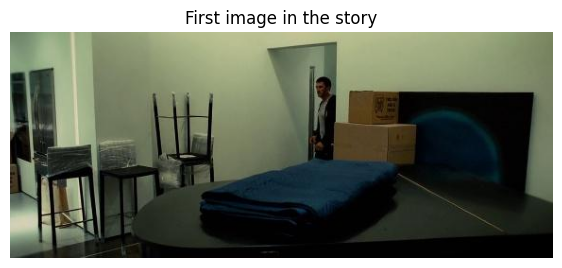

In [19]:

import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

first_image = sample["images"][0]

if isinstance(first_image, dict):
    if first_image.get("bytes") is not None:
        first_image = Image.open(
            BytesIO(first_image["bytes"])
        )
    elif first_image.get("path"):
        first_image = Image.open(first_image["path"])

plt.figure(figsize=(7, 5))
plt.imshow(first_image)
plt.axis("off")
plt.title("First image in the story")
plt.show()


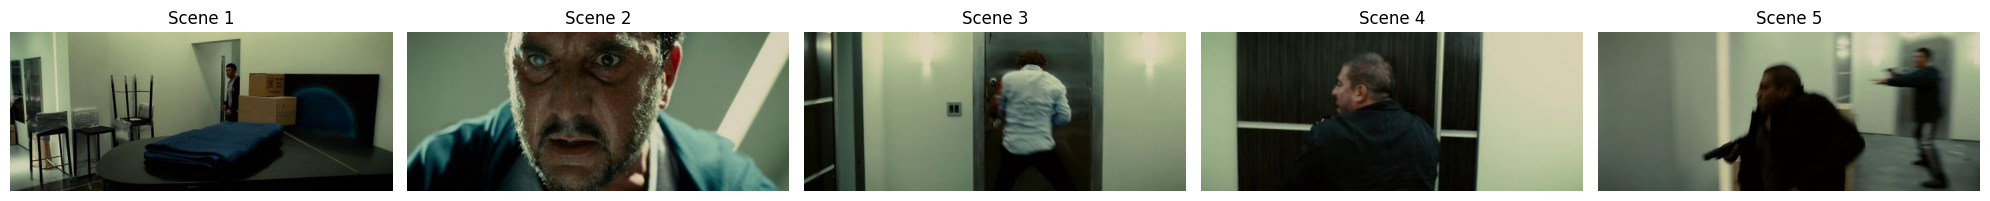

In [20]:

import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

sample = dataset["train"][0]

images = sample["images"]

num_images = min(5, len(images))

fig, axes = plt.subplots(
    1, num_images,
    figsize=(4 * num_images, 4),
    squeeze=False
)

for i in range(num_images):
    image = images[i]

    if isinstance(image, dict):
        if image.get("bytes") is not None:
            image = Image.open(BytesIO(image["bytes"]))
        elif image.get("path"):
            image = Image.open(image["path"])

    axes[0, i].imshow(image)
    axes[0, i].set_title(f"Scene {i + 1}")
    axes[0, i].axis("off")

plt.tight_layout()
plt.show()


In [21]:

print("Story ID:", sample["story_id"])
print("Frame count:", sample["frame_count"])

print("\nSTORY TEXT:")
print(str(sample["story"])[:3000])

print("\nCHAIN OF THOUGHT:")
print(str(sample["chain_of_thought"])[:1500])


Story ID: 3920
Frame count: 17

STORY TEXT:
<gdi image1>
In the sterile environment of a sparse room filled with <gdo obj1>cardboard boxes</gdo>, <gdo obj5>a blue blanket</gdo>, and <gdo bg26>a table</gdo>, <gdo char1>James</gdo> <gda char1>enters</gda> with a neutral look. His face reflects the calm before the storm. <gdo char1>James</gdo> <gda char1>enters</gda> an empty room that holds the remnants of what looks like a hastily abandoned office. The room's <gdl bg1>neutral lighting</gdl> and <gdl bg2>simple, minimalistic architecture</gdl> add to the eerie silence. <gdo char1>James</gdo> <gda char1>looks around</gda> with a sense of purpose, as if searching for something or someone.
</gdi>

<gdi image2>
Suddenly, the stillness is shattered by the appearance of <gdo char3>Jack</gdo>. <gdo char3>Jack</gdo> <gda char3>looks around</gda> with an intense, concerned expression. His eyes dart around the room, suggesting he's on high alert. The atmosphere thickens with tension as <gdo char3>

In [22]:

import re

story_text = sample["story"]

tags = re.findall(
    r"<gdi image\d+>",
    story_text
)

print("Image description tags:")
print(tags)

print("\nNumber of tags:", len(tags))
print("Number of images:", len(sample["images"]))


Image description tags:
['<gdi image1>', '<gdi image2>', '<gdi image3>', '<gdi image4>', '<gdi image5>', '<gdi image6>', '<gdi image7>', '<gdi image8>', '<gdi image9>', '<gdi image10>', '<gdi image11>', '<gdi image12>', '<gdi image13>', '<gdi image14>', '<gdi image15>', '<gdi image16>', '<gdi image17>']

Number of tags: 17
Number of images: 17


In [23]:

pattern = r"<gdi image(\d+)>(.*?)</gdi>"

matches = re.findall(
    pattern,
    story_text,
    flags=re.DOTALL
)

scene_descriptions = {
    int(number): description.strip()
    for number, description in matches
}

print("Descriptions extracted:", len(scene_descriptions))

for number in sorted(scene_descriptions)[:5]:
    print(f"\nScene {number}:")
    print(scene_descriptions[number][:400])


Descriptions extracted: 17

Scene 1:
In the sterile environment of a sparse room filled with <gdo obj1>cardboard boxes</gdo>, <gdo obj5>a blue blanket</gdo>, and <gdo bg26>a table</gdo>, <gdo char1>James</gdo> <gda char1>enters</gda> with a neutral look. His face reflects the calm before the storm. <gdo char1>James</gdo> <gda char1>enters</gda> an empty room that holds the remnants of what looks like a hastily abandoned office. The r

Scene 2:
Suddenly, the stillness is shattered by the appearance of <gdo char3>Jack</gdo>. <gdo char3>Jack</gdo> <gda char3>looks around</gda> with an intense, concerned expression. His eyes dart around the room, suggesting he's on high alert. The atmosphere thickens with tension as <gdo char3>Jack</gdo> <gda char3>realizes</gda> he's not alone. The room's <gdl bg3>plain interior</gdl> amplifies the sense o

Scene 3:
With a heavy heart, <gdo char1>James</gdo> <gda char1>enters</gda> an elevator, his mind racing with thoughts of what might be waiting for <g

In [24]:

num_images = len(sample["images"])
num_descriptions = len(scene_descriptions)

print("Images:", num_images)
print("Descriptions:", num_descriptions)

if num_images == num_descriptions:
    print("Counts match!")
else:
    print("Counts differ - inspect the story formatting.")


Images: 17
Descriptions: 17
Counts match!



SCENE 1


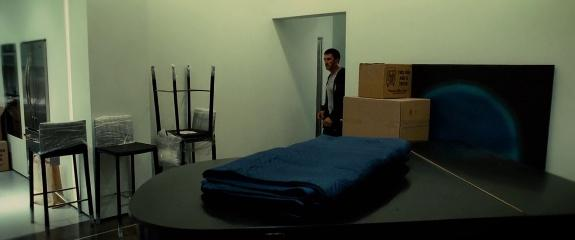

Description:
In the sterile environment of a sparse room filled with <gdo obj1>cardboard boxes</gdo>, <gdo obj5>a blue blanket</gdo>, and <gdo bg26>a table</gdo>, <gdo char1>James</gdo> <gda char1>enters</gda> with a neutral look. His face reflects the calm before the storm. <gdo char1>James</gdo> <gda char1>enters</gda> an empty room that holds the remnants of what looks like a hastily abandoned office. The room's <gdl bg1>neutral lighting</gdl> and <gdl bg2>simple, minimalistic architecture</gdl> add to the eerie silence. <gdo char1>James</gdo> <gda char1>looks around</gda> with a sense of purpose, as if searching for something or someone.

SCENE 2


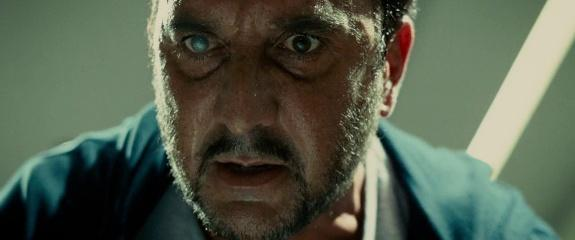

Description:
Suddenly, the stillness is shattered by the appearance of <gdo char3>Jack</gdo>. <gdo char3>Jack</gdo> <gda char3>looks around</gda> with an intense, concerned expression. His eyes dart around the room, suggesting he's on high alert. The atmosphere thickens with tension as <gdo char3>Jack</gdo> <gda char3>realizes</gda> he's not alone. The room's <gdl bg3>plain interior</gdl> amplifies the sense of danger, and <gdo char3>Jack</gdo> <gda char3>starts</gda> to feel the weight of an impending threat.

SCENE 3


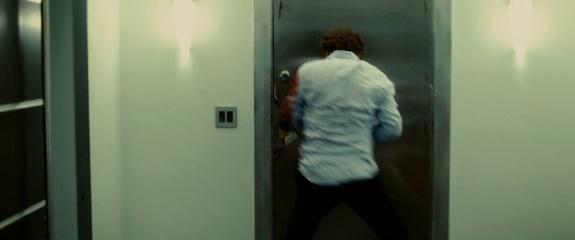

Description:
With a heavy heart, <gdo char1>James</gdo> <gda char1>enters</gda> an elevator, his mind racing with thoughts of what might be waiting for <gdo char1>him</gdo> on the other side. The <gdo obj7>elevator</gdo> seems to move slowly, each second feeling like an eternity. <gdo char1>James</gdo> <gda char1>wonders</gda> if he's made the right decision to come here. The confined space of the elevator adds to the claustrophobic feeling, and <gdo char1>James</gdo> <gda char1>tries</gda> to gather <gdo char1>his</gdo> thoughts in preparation for what lies ahead.


In [25]:

from IPython.display import display

for i in range(min(3, len(sample["images"]))):
    print(f"\nSCENE {i + 1}")

    display(sample["images"][i])

    print("Description:")
    print(
        scene_descriptions.get(
            i + 1,
            "No description found"
        )
    )


In [26]:

print("Story ID:", sample["story_id"])
print("Total images:", len(sample["images"]))
print("Descriptions:", len(scene_descriptions))

image_numbers = set(range(1, len(sample["images"]) + 1))
description_numbers = set(scene_descriptions.keys())

print("Missing descriptions:",
      sorted(image_numbers - description_numbers))

print("Extra descriptions:",
      sorted(description_numbers - image_numbers))


Story ID: 3920
Total images: 17
Descriptions: 17
Missing descriptions: []
Extra descriptions: []


In [27]:

context_length = 3

input_images = sample["images"][:context_length]

input_texts = [
    scene_descriptions[i]
    for i in range(1, context_length + 1)
]

target_image = sample["images"][context_length]
target_text = scene_descriptions[context_length + 1]

print("Input images:", len(input_images))
print("Input descriptions:", len(input_texts))

print("\nFirst input description:")
print(input_texts[0][:300])

print("\nTarget description:")
print(target_text[:300])


Input images: 3
Input descriptions: 3

First input description:
In the sterile environment of a sparse room filled with <gdo obj1>cardboard boxes</gdo>, <gdo obj5>a blue blanket</gdo>, and <gdo bg26>a table</gdo>, <gdo char1>James</gdo> <gda char1>enters</gda> with a neutral look. His face reflects the calm before the storm. <gdo char1>James</gdo> <gda char1>ent

Target description:
The elevator doors open, and <gdo char4>Alex</gdo> <gda char4>stands</gdo> in the hallway. <gdo char4>Alex</gdo> <gda char4>looks</gda> alert, as if he's been expecting <gdo char1>James</gdo>. The hallway, with its <gdl bg4>plain modern architecture</gdl>, feels cold and unwelcoming. <gdo char4>Alex


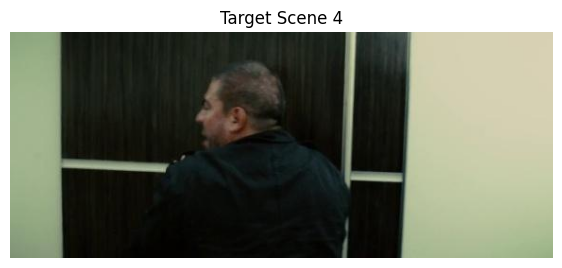

In [28]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.imshow(target_image)
plt.axis("off")
plt.title("Target Scene 4")
plt.show()


In [29]:

image_count = len(sample["images"])
description_count = len(scene_descriptions)

expected = set(range(1, image_count + 1))
actual = set(scene_descriptions.keys())

print("Images:", image_count)
print("Descriptions:", description_count)
print("Missing scene numbers:", sorted(expected - actual))
print("Extra scene numbers:", sorted(actual - expected))

print("Alignment valid:", expected == actual)


Images: 17
Descriptions: 17
Missing scene numbers: []
Extra scene numbers: []
Alignment valid: True
